# ReadData: 生データの読み込みとイベント同期

SMILE-2+ の生データは**検出器(ボード)ごとに別ファイル**です。

| ファイル | 中身 |
|---|---|
| `uTPC_anode{1..3}_*.raw` | TPC アノード 3 ボード: ヒットしたストリップ・クロック(エンコーダ)と FADC 波形 4 ch ずつ |
| `uTPC_cathode{1..3}_*.raw` | TPC カソード 3 ボード: 同上 |
| `HA{id}_*.raw` | シンチレータ(HA)モジュール 18 台: PMT 6 本 × 4 ch の ADC |

`ReadData` はこれらを 1 イベントずつ読み、**全ボードのイベント番号がそろうまで遅れているボードを読み進めて**同期させます
(そろうまでに読み飛ばしが起きたイベントは `IDcheck_Loopback` フラグが立ちます)。
SMILE_tool_box の `RawRead2p` に相当します。

> 実行時間の大部分は生データの読み込みです。ネットワーク越しの場所から読むと数倍〜10 倍遅くなるので、
> データは手元のディスクにコピーして使うことをおすすめします(1 節)。

### パラメータ

| パラメータ | 値 | 意味 |
|---|---|---|
| `data_dir` | `.../sm2+_cal_rawdata/20190701_Per02` | 生データのディレクトリ |
| `reverse_TPC` | `True` | TPC のストリップ番号の向きを反転する(SMILE-2+ の配線に合わせる) |
| `TPC_Only` | `False` | `True` なら HA を読まない |

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials_caldata" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> 2 次元の numpy 配列"""
    return np.stack([np.asarray(v) for v in column])

## 1. データの準備

データ(20190701 の較正データ **Per02**)の入手方法と置き場所は、
**[1_DataIO のノートブック](../../DataIO_example.ipynb) の「1. データの準備」**を見てください。
NAS を読める計算機では、ここでは何もする必要はありません。

下のセルで、設定ファイル `config/smile2p_20190701_Per02.json` が指すデータが見つかるかだけ確認します
(`MISSING` と出たら 1_DataIO の 1 節を見てください)。

In [2]:
CONFIG = "smile2p_20190701_Per02"
cfg = ec.load(CONFIG)
print("data_top:", ec.data_top())
for path in [cfg["parameters"]["ReadData"]["data_dir"], cfg["parameters"]["HA_Calc"]["parameter_dir"]]:
    print("OK     " if Path(path).is_dir() else "MISSING", path)

data_top: /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/sm2+_cal_rawdata/20190701_Per02
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/param/20190528


## 2. 生データツリーを作る

モジュールの出力ファイルには図(ヒストグラム)を保存せず、TTree だけを書きます。
処理の中身を確かめる図は、`ReadData → RawTreeWriter` で作る**生データツリー**(`RawTreeWriter/raw`)から描きます。
中身は `../8_RawTreeWriter/` を参照してください。ここでは Per02 の先頭 5000 イベントを使います。

ターミナル(コマンドプロンプト)では、リポジトリの `run_script` ディレクトリで次を実行するのと同じです。

```bash
cd EricaNext_try/run_script
python3 run_chain.py smile2p_20190701_Per02 -o Per02_raw_5000.root -n 5000 --raw --compression 505
```

| 引数 | 意味 |
|---|---|
| `smile2p_20190701_Per02` | 設定ファイル `config/smile2p_20190701_Per02.json`(データの場所と各モジュールのパラメータ) |
| `-o Per02_raw_5000.root` | 出力ファイル |
| `-n 5000` | 先頭 5000 イベントだけ処理する(省略すると全イベント) |
| `--raw` | `ReadData → RawTreeWriter` だけを実行し、生データツリーを書く(再構成はしない) |
| `--compression 505` | ROOT の圧縮を zstd(レベル 5)にする。既定の圧縮より約 2 割小さくなる |

下のセルは同じコマンドを Python から実行しています(`sys.executable` は今のカーネルの python3、
`RUN_CHAIN` は `run_chain.py` のパス、`CONFIG` は設定名)。出力が既にあれば再実行しません。

In [3]:
# ReadData -> RawTreeWriter だけを実行して生データツリーを作る(先頭 5000 イベント、zstd 圧縮)
RAW = CACHE / "Per02_raw_5000.root"
cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(RAW), "-n", "5000", "--raw", "--compression", "505"]
print(" ".join(cmd))
if not RAW.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()

# ボード ID の一覧(別ツリー run_info に 1 行だけ入っている)
info = ROOT.RDataFrame("RawTreeWriter/run_info", str(RAW)).AsNumpy(["anode_ids", "cathode_ids", "ha_ids"])
HA_IDS = [int(x) for x in info["ha_ids"][0]]
print("HA modules:", HA_IDS)

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_20190701_Per02 -o /home/onoda/ANLNext/EricaNext_try/tutorials_caldata/cache/Per02_raw_5000.root -n 5000 --raw --compression 505


HA modules: [1, 2, 3, 7, 8, 9, 13, 14, 15, 19, 20, 21, 25, 26, 27, 31, 32, 33]


## 3. TPC のヒット

全イベントのヒットを積算したヒットマップ(横軸 ストリップ番号 0–383、縦軸 ドリフト方向のクロック)と、1 イベントの飛跡です。
アノードとカソードはそれぞれ x, y 方向のストリップ(ピッチ 0.8 mm)で、クロックがドリフト時間(z 方向)になります。

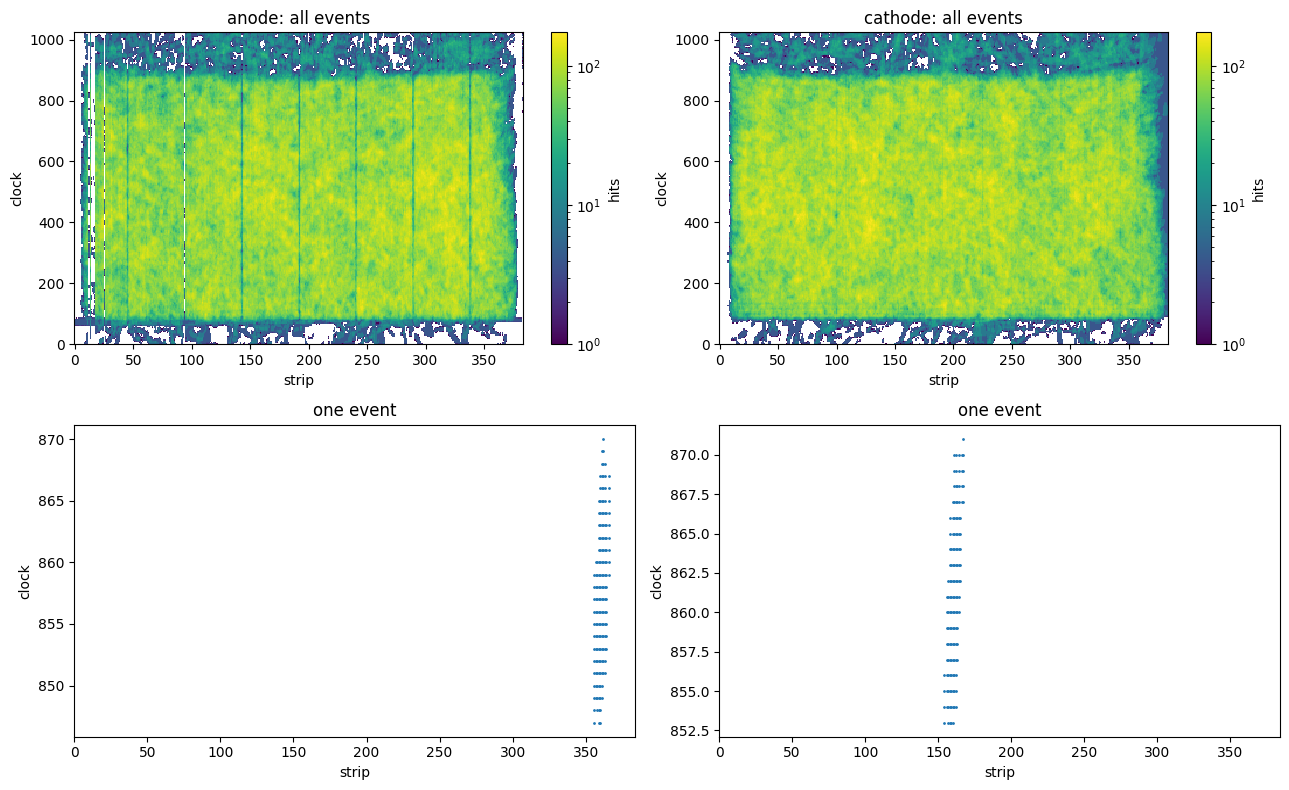

In [4]:
d = ROOT.RDataFrame("RawTreeWriter/raw", str(RAW)).AsNumpy(["hit_a_strip", "hit_a_clock", "hit_c_strip", "hit_c_clock"])
hits = {k: [np.asarray(v) for v in col] for k, col in d.items()}   # イベントごとのヒットの配列

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for k, side in enumerate("ac"):
    strip, clock = np.concatenate(hits[f"hit_{side}_strip"]), np.concatenate(hits[f"hit_{side}_clock"])
    h = ax[0, k].hist2d(strip, clock, bins=[384, 256], range=[[-0.5, 383.5], [0, 1024]], cmin=1, norm="log")
    fig.colorbar(h[3], ax=ax[0, k], label="hits")
    ax[0, k].set_title(f"{'anode' if side == 'a' else 'cathode'}: all events")
    ax[1, k].plot(hits[f"hit_{side}_strip"][19], hits[f"hit_{side}_clock"][19], ".", ms=2)
    ax[1, k].set_title("one event"); ax[1, k].set_xlim(0, 384)
    for a in ax[:, k]: a.set_xlabel("strip"); a.set_ylabel("clock")
fig.tight_layout(); plt.show()

## 4. TPC の FADC 波形

FADC はボードごとに 4 ch あり、各 ch は 32 ストリップ分の信号の和です(アノード 12 ch、カソード 12 ch)。
アノード ch 0 とカソード ch 0 の波形を重ね描きします(横軸 サンプル番号、縦軸 ADC 値)。これを `CalcFADC` が電荷に変換します。

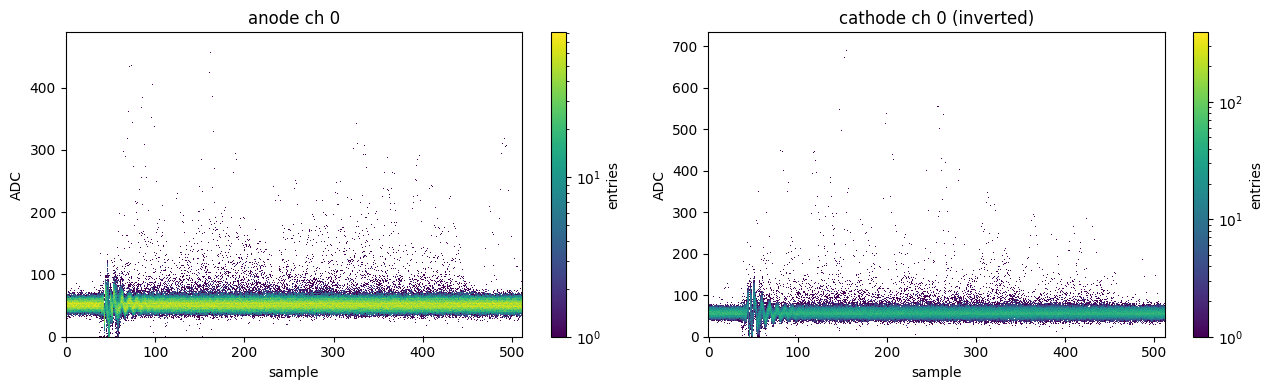

In [5]:
d = ROOT.RDataFrame("RawTreeWriter/raw", str(RAW)).Range(2000).AsNumpy(["fadc_ch", "fadc_wave"])
acc = {0: np.zeros((512, 1024)), 12: np.zeros((512, 1024))}
for ch, w in zip(d["fadc_ch"], d["fadc_wave"]):
    ch = list(np.asarray(ch)); w = np.asarray(w).reshape(len(ch), 512)   # 1 行 = 保存した ch × 512 サンプル
    for c in acc:
        if c in ch:
            y = np.clip(w[ch.index(c)].astype(int), 0, 1023)
            acc[c][np.arange(512), y] += 1
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (c, lab) in zip(ax, [(0, "anode ch 0"), (12, "cathode ch 0 (inverted)")]):
    v = acc[c]; iy = np.nonzero(v.sum(0))[0]
    m = a.pcolormesh(np.arange(513) - 0.5, np.arange(1025) - 0.5, np.where(v > 0, v, np.nan).T, norm="log")
    fig.colorbar(m, ax=a, label="entries")
    a.set_ylim(iy.min(), iy.max() + 1); a.set_title(lab); a.set_xlabel("sample"); a.set_ylabel("ADC")
fig.tight_layout(); plt.show()

## 5. HA の ADC

HA01 モジュールの 24 ch(PMT 6 本 × 4 ch)の ADC 分布を、エラービットが立っていないもの(OK)と立っているもの(NG)に分けて描きます。

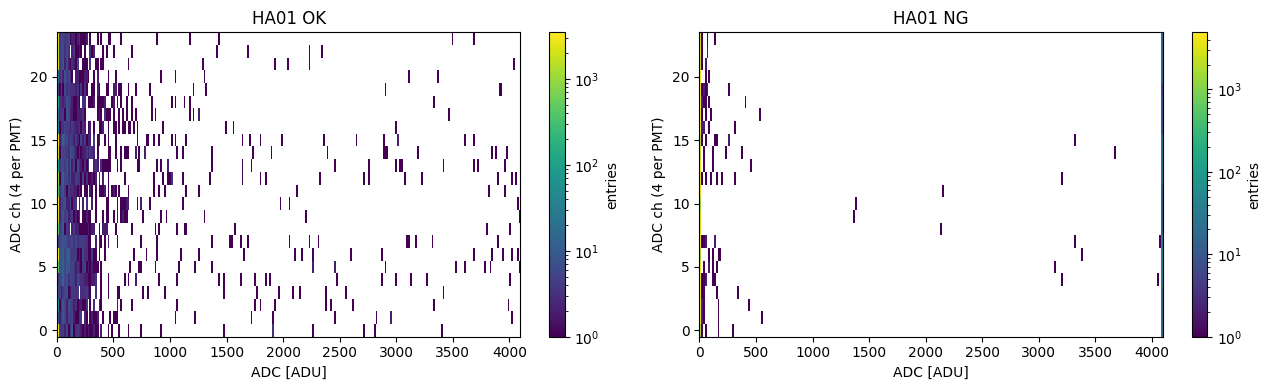

In [6]:
d = (ROOT.RDataFrame("RawTreeWriter/raw", str(RAW))
     .Define("ha_err_i", "ROOT::RVecI(ha_err.begin(), ha_err.end())")   # vector<char> -> int
     .AsNumpy(["ha_adc", "ha_err_i"]))
adc = vec(d["ha_adc"]).reshape(-1, len(HA_IDS), 24).astype(float)   # [イベント, HA, ch]
err = vec(d["ha_err_i"]).reshape(-1, len(HA_IDS), 24).astype(bool)
ha = HA_IDS.index(1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, sel, lab in [(ax[0], ~err[:, ha], "OK"), (ax[1], err[:, ha], "NG")]:
    ch = np.broadcast_to(np.arange(24), adc[:, ha].shape)
    h = a.hist2d(adc[:, ha][sel], ch[sel], bins=[256, 24], range=[[0, 4096], [-0.5, 23.5]], cmin=1, norm="log")
    fig.colorbar(h[3], ax=a, label="entries")
    a.set_title(f"HA01 {lab}"); a.set_xlabel("ADC [ADU]"); a.set_ylabel("ADC ch (4 per PMT)")
fig.tight_layout(); plt.show()